# 01 — Task Analysis: The Well `turbulent_radiative_layer_2D`

**Benchmark:** The Well (arXiv:2412.00568, NeurIPS D&B). Radiatively cooled turbulent mixing layers — cold dense gas below, hot dilute gas above; the shear interface develops chaotic mixing whose evolution depends on cooling time `t_cool` (9 regimes). Fields: density, pressure, velocity (x,y). Official metric **VRMSE** (1.0 = as good as predicting the spatial mean).

**Our subset:** 3 regimes spanning the range (t_cool 0.03 / 0.56 / 3.16), train+valid, downsampled 2x to 64x192 for the sprint loop.

In [1]:
import sys, pathlib, glob, re, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path().resolve().parent
sys.path.insert(0, str(ROOT / 'paper'))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
DEVICE = 'cpu'   # GPU reserved for the sprint queue; flip when free
torch.manual_seed(0)


In [2]:
from data import load, vrmse
train, valid, mean, std = load()
print('train', tuple(train.shape), '(traj, T, C, H, W)')
print('valid', tuple(valid.shape))
print('channels: density, pressure, vx, vy (z-scored)')

train (24, 101, 4, 64, 192) (traj, T, C, H, W)
valid (3, 101, 4, 64, 192)
channels: density, pressure, vx, vy (z-scored)


## What the fields look like
Early, middle and late snapshots of one trajectory — the mixing layer develops fine chaotic structure over time.

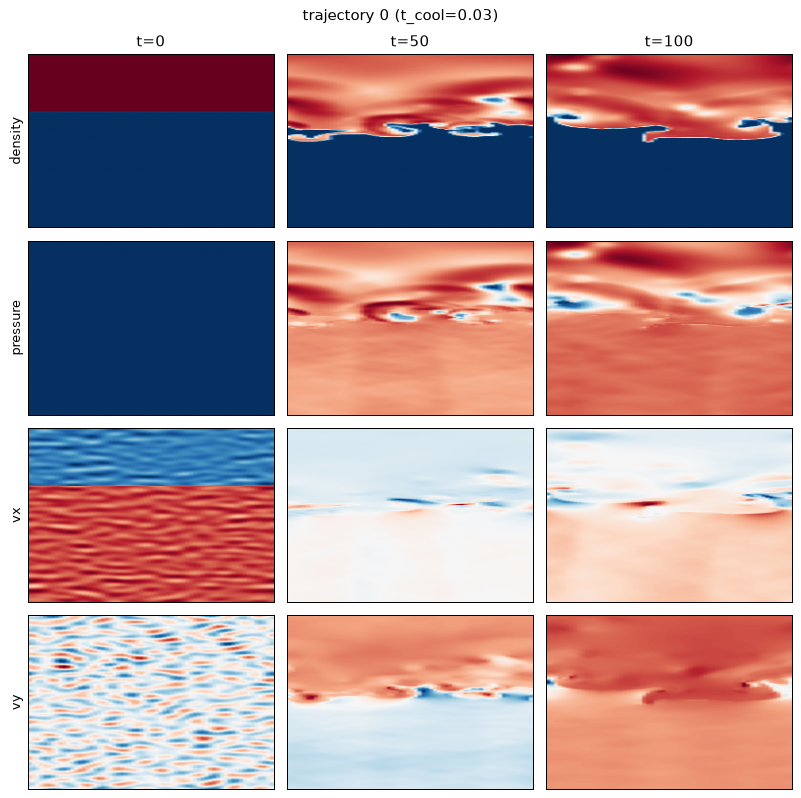

In [3]:
fig, ax = plt.subplots(4, 3, figsize=(9, 9))
names = ['density', 'pressure', 'vx', 'vy']
for c in range(4):
    for j, t in enumerate([0, 50, 100]):
        ax[c, j].imshow(train[0, t, c].T, cmap='RdBu_r', aspect='auto')
        ax[c, j].set_xticks([]); ax[c, j].set_yticks([])
        if c == 0: ax[c, j].set_title(f't={t}')
        if j == 0: ax[c, j].set_ylabel(names[c])
plt.suptitle('trajectory 0 (t_cool=0.03)'); plt.tight_layout(); plt.show()

## Why it is hard: growing temporal change + chaotic mixing

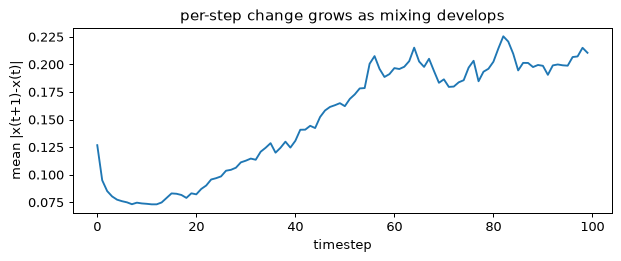

In [4]:
d = (train[:, 1:] - train[:, :-1]).abs().mean(dim=(0, 2, 3, 4))
plt.figure(figsize=(7, 3))
plt.plot(d.numpy()); plt.xlabel('timestep'); plt.ylabel('mean |x(t+1)-x(t)|')
plt.title('per-step change grows as mixing develops'); plt.tight_layout(); plt.show()

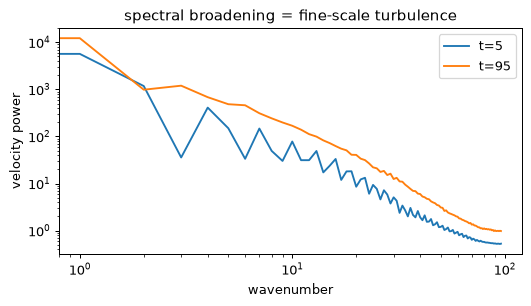

In [5]:
# energy spectrum flattens as turbulence develops fine scales
def spec(v):
    f = torch.fft.rfft(v, dim=-1).abs().square().mean(dim=(0, 1))
    return f.mean(dim=0)
s0 = spec(train[:, 5, 2:4]); s1 = spec(train[:, 95, 2:4])
plt.figure(figsize=(6, 3.5))
plt.loglog(s0.numpy(), label='t=5'); plt.loglog(s1.numpy(), label='t=95')
plt.xlabel('wavenumber'); plt.ylabel('velocity power'); plt.legend()
plt.title('spectral broadening = fine-scale turbulence'); plt.tight_layout(); plt.show()

## Trivial floors every model must beat

In [6]:
pers1, pers8 = [], []
for t in range(0, valid.shape[1] - 9, 8):
    x = valid[:, t]
    pers1.append(vrmse(x, valid[:, t + 1]).item())
    pers8.append(vrmse(x, valid[:, t + 8]).item())
print(f'persistence  VRMSE@1: {np.mean(pers1):.3f}   VRMSE@8: {np.mean(pers8):.3f}')
print('mean-predictor VRMSE = 1.0 by construction')

persistence  VRMSE@1: 0.583   VRMSE@8: 1.002
mean-predictor VRMSE = 1.0 by construction


## Published numbers on the FULL official protocol (context)

| model | one-step TEST | rollout 6:12 | rollout 13:30 |
|---|---|---|---|
| CNextU-net ~18M | **0.1956** | 0.54 | 1.01 |
| U-Net classic | 0.2418 | 0.66 | 1.04 |
| FNO | 0.5001 | 1.79 | 3.54 |
| TFNO | 0.5016 | 6.01 | >10 |
| Walrus 1.3B (median protocol) | 0.0831 | — | 0.339 @T[1:20] |

**Takeaways.** (1) Even 1.3B-param foundation models exceed VRMSE 1.0 at long horizons — rollout stability is the open flank. (2) Our sprint numbers use an easier internal protocol (1-frame input, downsampled, valid split) — comparable to each other, not to this table, until the protocol-faithful trainer (scoreboard H1d) runs.